## Data Augmentation(데이터 증강) 개요
- CNN Model의 성능을 높이고, **over fitting을 극복**할 수 있는 가장 좋은 방법은 <br>
  이미지 데이터의 경우 **학습 데이터의 양을 늘리는 것임.**

- 그러나 이미지 데이터의 경우 학습데이터의 양을 늘리기 쉽지 않기 때문에, <br>
  학습 시에 **원본 이미지에 다양한 변형을 가해서 학습 이미지 데이터를 늘리는 것과 유사한 효과**를 발휘하게끔 한다.
 
- 다시 말해, <br>
  Data Augumentation은 **원본 학습 이미지의 개수를 늘리는 것이 아닌**, <br>
  **학습 시마다 개별 원본 이미지를 변형**해서 **학습을 수행**하는 것임.

### **Augmentation 유형 : 공간(spatial)레벨, 픽셀(pixel)레벨**
**공간(spatial)레벨 변형**
- Flip: Vertical(up/down), Horizontal(left/right)
- Crop: Center, Random
- Affine: Rotate, Translate, Shear, Scale(Zoom)

**픽셀(pixel)레벨 변형**
- Bright:
- Contrast:
- Blur, Gaussian Blur, Median Blur
- Noise, Cutout
- Histogram
- Gamma
- RGBShift
- Sharpen

### ImageDataGenerator 변환 유형

#### Flip
- horizontal_flip = True (좌우 반전)
- vertical_flip = True (상하 반전)

#### Rotation
- rotation_range = 45
- 임의의 -45 ~ +45 의 angle 회전  

#### Shift
- width_shift_range = 0.2
- height_shift_range = 0.2
- 0 ~ 1 사이 값을 설정하여 좌우,상하를 이동

#### Zoom
- zoom_range=[0.5, 1.5]
- 1보다 작은 값은 확장, 1보다 큰 값은 축소

#### Shear
- shear_range = 45
- x 또는 y축을 중심으로 0~45 도 사이 변환

#### Bright
- brightness_range = (0.1, 0.9)
- brightness_range로 밝기 조절
- 0~1 사이 값 입력, 0에 가까울수록 어둡고, 1에 가까울수록 밝음

#### Channel Shift
- channel_shift_range = 120
- R,G,B pixel 값을 -120 ~ +120 사이의 임의의 값을 더하여 변환

#### ZCA Whitening
zca_whitening = True
zca_epilson = 1e-6
zca 변환으로 whitening 효과
keras 버그로 인해 사용 유의

#### Normalization
- feature_center = True
- featurewise_std_nomalization = True
- 각 R,.G, B pixel값에서 개별 채널 별 표준편차 pixel값을 나눔
-  rescale=1/255.0 딥러닝 입력은 비교적 작은 값을 선호하므로 0~255 사이의 pixel 값을 0~1 사이의 값으로 변환

In [ ]:
import numpy as np  # linear algebra
import pandas as pd   # data processing, CSV file I/O (e.g pd.read_c\v)   
import os

In [4]:
!wget -O puppy.jpg https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=300

--2026-10-30 12:37:26--  https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=300
Resolving images.unsplash.com (images.unsplash.com)... 151.101.194.208, 151.101.66.208, 151.101.2.208, ...
Connecting to images.unsplash.com (images.unsplash.com)|151.101.194.208|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14406 (14K) [image/jpeg]
Saving to: ‘puppy.jpg’

puppy.jpg           100%[===================>]  14.07K  --.-KB/s    in 0.001s  

2026-10-30 12:37:26 (21.3 MB/s) - ‘puppy.jpg’ saved [14406/14406]



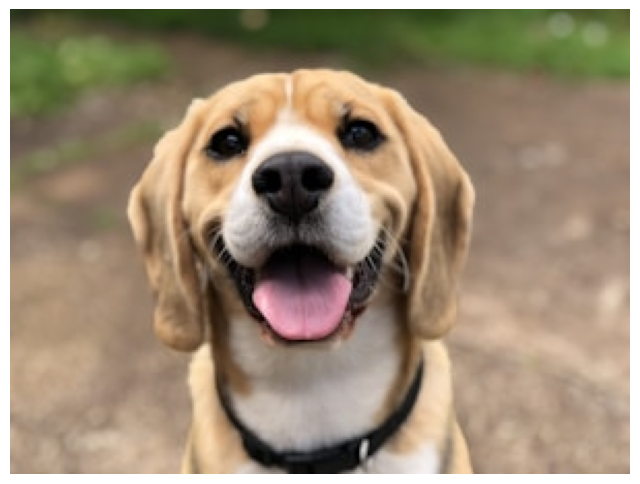

In [5]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

image = cv2.cvtColor(cv2.imread('puppy.jpg'), cv2.COLOR_BGR2RGB)

def show_image(image):
    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis('off')

show_image(image)

## ImagDataGenerator를 이용하여 Augmentation 적용하기
* ImageDataGenerator는 fit(), flow()를 통해서 입력된 image array(numpy)를 변환 동작시킬 수 있으며, 실제 변환은 next()등으로 iteration 호출해야 함
* ImageDataGenerator가 입력으로 받는 image array는 batch를 포함한 4차원 array임. 즉 [579, 1028, 3] shape인 image array가 입력되면 이를 4차원 형태인 [1, 579, 1028, 3] 으로 변경해야 함.
* 변경된 pixel값은 float이므로 이를 다시 int형으로 변경해서 시각화 필요.

### 좌우, 상하 반전(Horizontal Flip, Vertical Flip)
* horizontal_flip=True로 좌우 반전 적용. 하지만 반드시 변환하는 것은 아니며 Random하게 원본 데이터를 유지하거나 변환 결정
* vertical_flip=True로 상하 반전 적용. 마찬가지로 반드시 변환하는 것은 아니며 Random하게 원본 데이터를 유지하거나 변환 결정

In [ ]:
# ImageDataGenerator를 이용한 Augmentation
'''
ImageDataGenerator(
featurewise_center=False, samplewise_center=False, 
featurewise_std_normalization=False, 
samplewise_std_normalization=False, 
zca_whitening=False, zca_epsilon=1e-06,
rotation _range=0,                              # Rotation(§/21)
width_ shift range=0.0, height_shift_range=0.0, # Shift(Translate)
brightness_range=None,                          # Bright(217|)
Shear_range =0.0, # Shear zoom_range=0.0,       # Zoom(Scale)
Channel_shift_range=0.0,                        # Channel Shift
fill_mode='nearest,                             # 빈공간 채우는 방법
cval=0.0,
horizontal_flip=False, vertical flip=False,     # Flip(좌우,상하 반전)
rescale=None,
preprocessing_function=None, data_format=None, validation_split=0.0, dtype=None, )
'''

image_batch shape: (1, 225, 300, 3)
aug_image shape: (225, 300, 3)


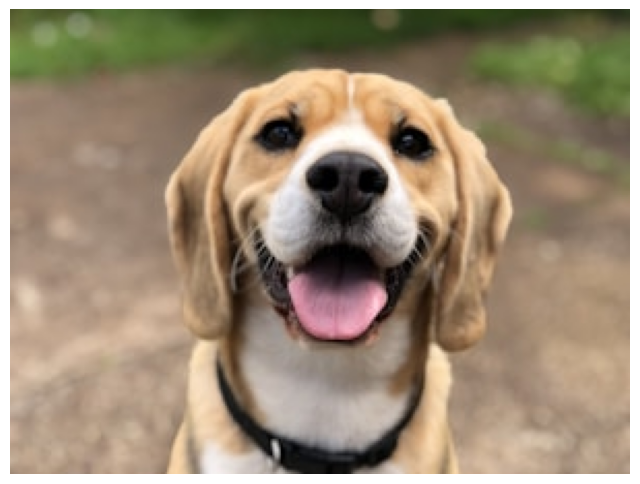

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Horizontal Flip(좌우 반전)을 적용. horizontal_flip=True을 적용했지만 반드시 변환하는 것은 아님. Random하게 원본 데이터를 유지하거나 변환 결정.
data_generator = ImageDataGenerator(horizontal_flip=True)

# ImageDataGenerator는 여러개의 Image를 입력으로 받음. 
# 따라서 3차원이 아니라 batch를 포함한 4차원 array를 입력받음. np.expand_dims()로 차원 증가.
image_batch = np.expand_dims(image, axis=0) 
print('image_batch shape:', image_batch.shape)

# ImageDataGenerator 적용. fit()후 flow()로 image batch를 넣어주어야 함.
data_generator.fit(image_batch)
data_gen_iter = data_generator.flow(image_batch)

# ImageDataGenerator를 동작하기 위해서는 next()등으로 iteration을 호출해야함
aug_image_batch = next(data_gen_iter)

# 반환된 데이터는 batch까지 포함된 4차원 array이므로 다시 3차원 image array로 변환.
aug_image = np. squeeze(aug_image_batch)
print('aug_image shape:',aug_image. shape)

# 반환된 pixel 값은 float임. 이를 다시 int형으로 변경 후, 이미지 시각화
aug_image = aug_image.astype('int')
show_image(aug_image)

### 여러 이미지의 ImageDataGenerator 변환을 수행하는 함수 생성
- ImageDataGenerator는 next()로 호출이 될 때 마다 Random하게 Augmentation 적용이 설정되어 변환됨.

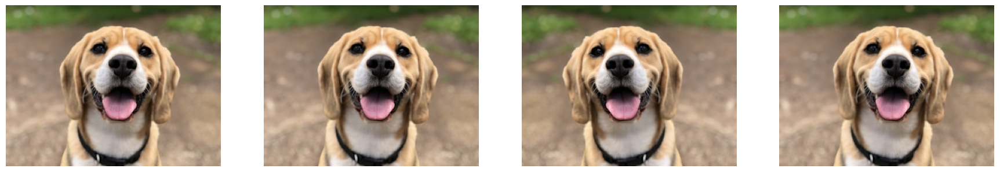

In [8]:
N_IMAGES = 4
fig, axs = plt.subplots(nrows=1, ncols=N_IMAGES, figsize=(22, 8))

for i in range(N_IMAGES):
    aug_image_batch = next(data_gen_iter)
    aug_image = np.squeeze(aug_image_batch)
    aug_image = aug_image.astype('int')
    axs[i].imshow(aug_image)
    axs[i].axis('off')

In [9]:
# ImageDataGenerator 객체를 입력하면 augmentation 적용된 일련의 image들을 시각화 해주는 함수 생성. 
def show_aug_image_batch(image, data_generator, n_images=4, to_int=True):
    
    image_batch = np.expand_dims(image, axis=0)
    # ImageDataGenerator 적용. fit()후 flow()로 image batch를 넣어주어야 함. 
    data_generator.fit(image_batch)
    data_gen_iter = data_generator.flow(image_batch)
    
    fig, axs = plt.subplots(nrows=1, ncols=n_images, figsize=(6*n_images, 8))

    for i in range(n_images):
        aug_image_batch = next(data_gen_iter)
        aug_image = np.squeeze(aug_image_batch)
        if(to_int):
            aug_image = aug_image.astype('int')
        axs[i].imshow(aug_image)
        axs[i].axis('off')


## 공간(spatial)레벨 변환 기법 <br>
- Flip, Rotation, Shift, Zoom(Scale), Shear 

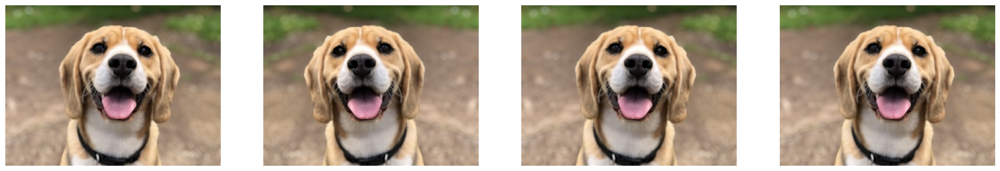

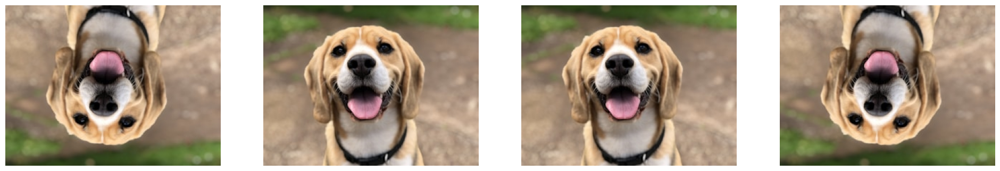

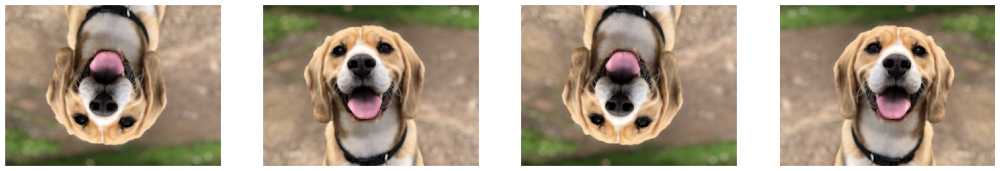

In [10]:
# Horizontal Flip(좌우 반전)을 적용. horizontal_flip=True을 적용했지만 반드시 변환하는 것은 아님. Random하게 원본 데이터를 유지하거나 변환 결정. 
data_generator = ImageDataGenerator(horizontal_flip=True)
show_aug_image_batch(image, data_generator, n_images=4)

# Vertical Flip(좌우 반전)을 적용. vertical_flip=True을 적용했지만 반드시 변환하는 것은 아님. Random하게 원본 데이터를 유지하거나 변환 결정. 
data_generator = ImageDataGenerator(vertical_flip=True)
show_aug_image_batch(image, data_generator, n_images=4)

# 두개를 함께 적용. 
data_generator = ImageDataGenerator(horizontal_flip=True, vertical_flip=True)
show_aug_image_batch(image, data_generator, n_images=4)

### 이미지 Rotation(회전) 적용

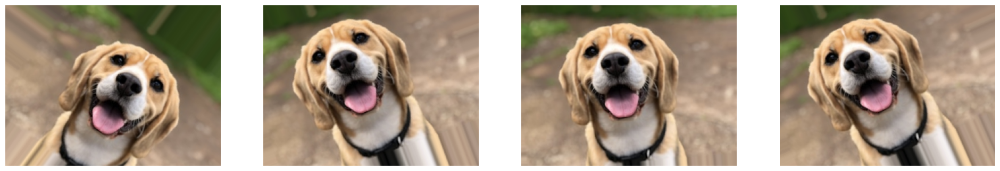

In [ ]:
data_gen = ImageDataGenerator(rotation_range=45)
show_aug_image_batch(image, data_gen, n_images=4)

### 이미지 좌우,상하 이동(Shift)
* width_shift_range, height_shift_range 입력 인자를 통해 좌우, 상하 이동. 
* width_shift_range, height_shift_range 값은 0 ~ 1 사이 값 부여. 수행 시 마다 전체 이미지 대비 해당 범위의 값 비율만큼 Random 하게 이동.
* 이동하게 되면 이동되고 남아있는 공간은 비어있게 되는데 이를 어떻게 채울치는 fill_mode 인자로 결정
* fill_mode는 아래와 같이 설정
* * nearest: 가장 빈공간에 가장 근접한 pixel로 채우기
* * reflect: 빈공간 만큼의 영역을 근처 공간으로 채우되 마치 거울로 반사되는 이미지를 보듯이 채움. 
* * wrap: 빈공간을 이동으로 잘려나간 이미지로 채움
* * constant: 특정 픽셀값으로 채움. 이때 특정 픽셀값은 cval 값으로 채움. cval=0 이면 검은색 픽셀로 채움


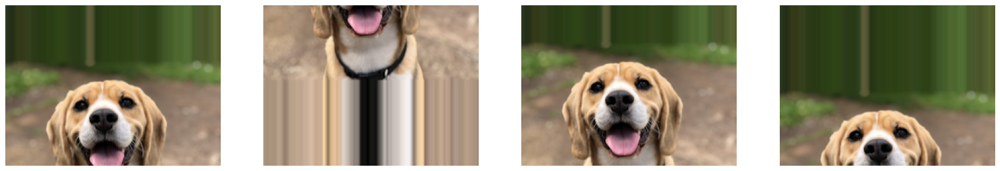

In [ ]:
# 왼쪽 또는 오른쪽으로 이미지 이동을 주어진 width_shift_range에 따라 random 하게 수행
data_generator = ImageDataGenerator(width_shift_range=0.4)
show_aug_image_batch(image, data_generator, n_images=4)

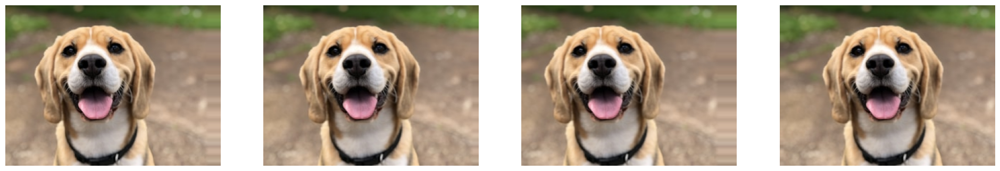

In [13]:
# 위쪽 또는 아래쪽 이미지 이동을 주어진 height_shift_range에 따라 random하게 수행
data_generator = ImageDataGenerator(height_shift_range=0.4)
show_aug_image_batch(image, data_generator, n_images=4)

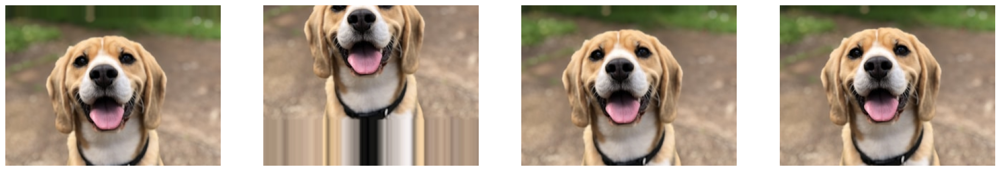

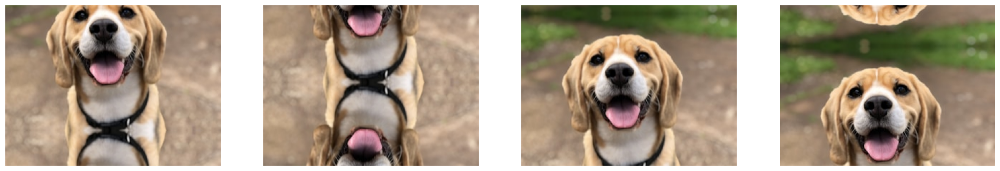

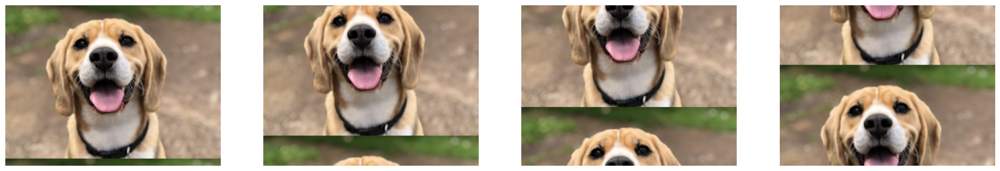

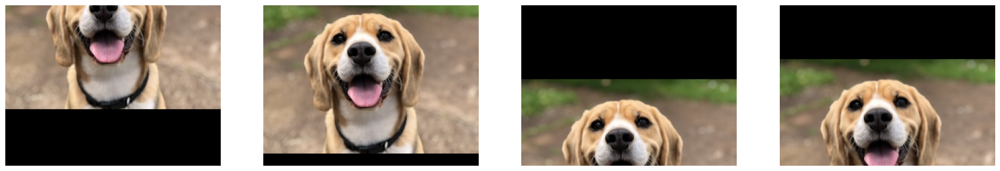

In [14]:
# 빈 공간을 가장 가까운 곳의 픽셀 값으로 채움
data_generator = ImageDataGenerator(width_shift_range=0.4, fill_mode='nearest')
show_aug_image_batch(image, data_generator, n_images=4)

# 빈 공간 만큼의 영역을 근처 공간으로 채움
data_generator = ImageDataGenerator(width_shift_range=0.4, fill_mode='reflect')
show_aug_image_batch(image, data_generator, n_images=4)

# 빈 공간을 이동으로 잘려나간 이미지로 채움
data_generator = ImageDataGenerator(width_shift_range=0.4, fill_mode='wrap')
show_aug_image_batch(image, data_generator, n_images=4)

# 특정 픽셀 값으로 채움, 이때 특정 픽셀값은 cval값으로 채움
data_generator = ImageDataGenerator(width_shift_range=0.4, fill_mode='constant', cval=0)
show_aug_image_batch(image, data_generator, n_images=4)

### Zoom(Scale) 적용
* Zoom은 zoom_range을 설정하여 적용. zoom_range가 1보다 작으면 확대(Zoom In), 1보다 크면 축소(Zoom Out)
* 축소 시 빈 공간은 fill_mode에 따라 픽셀을 채움. Default는 nearest 

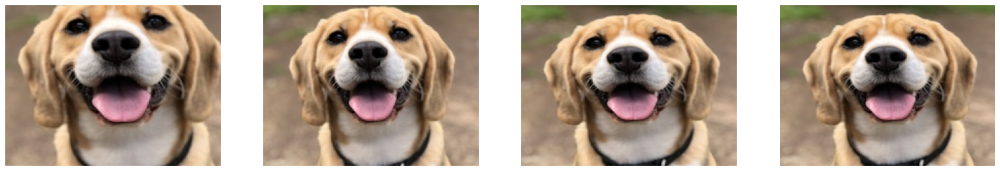

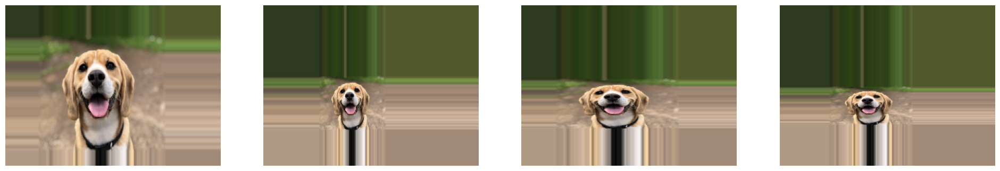

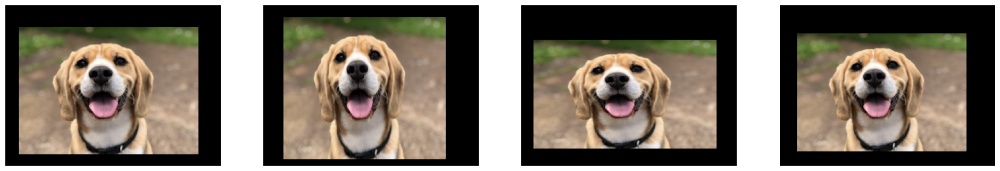

In [15]:
# Zoon In(확대)
data_generator = ImageDataGenerator(zoom_range=[0.5, 0.9])
show_aug_image_batch(image, data_generator, n_images=4)

# Zoom out(축소)
data_generator = ImageDataGenerator(zoom_range=[1.1, 4.5])
show_aug_image_batch(image, data_generator, n_images=4)

# Zoom out 시 비어 있는 공간 채우기
data_generator = ImageDataGenerator(zoom_range=[1.1, 1.5], fill_mode='constant', cval=0)
show_aug_image_batch(image, data_generator, n_images=4)

### Shear 적용
shear_range로 이용하여 적용. shear_range=45일 경우 -45 ~ 45 도 사이에서 변환 적용

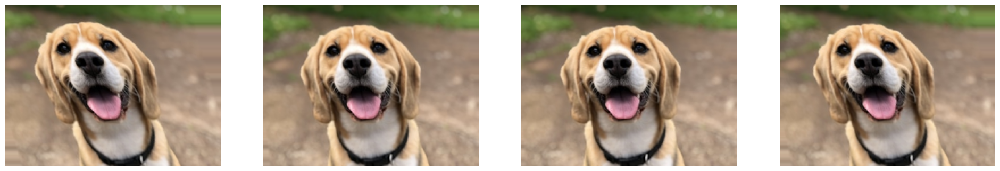

In [17]:
data_generator = ImageDataGenerator(shear_range=45)
show_aug_image_batch(image, data_generator, n_images=4)

### Bright 적용
brightness_range 로 밝기 조절. 0~1 사이 값이 입력 되며, 0에 가까울수록 원본 이미지 보다 더 어둡고, 1보다 커질 수록 원본 이미지 보다 밝음. 

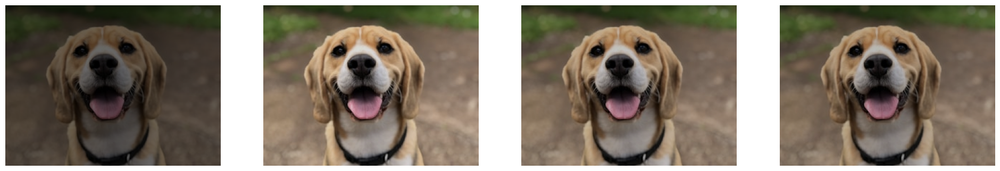

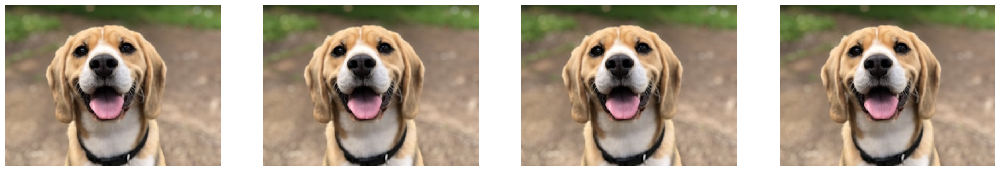

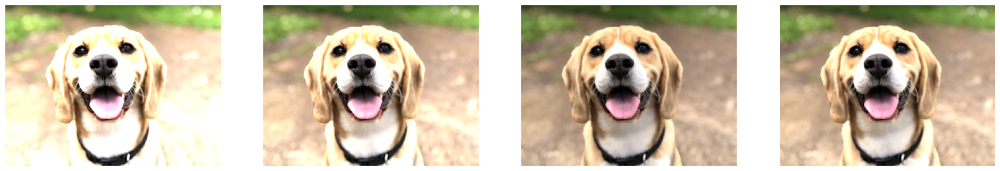

In [18]:
data_generator = ImageDataGenerator(brightness_range=(0.1, 0.9))
show_aug_image_batch(image, data_generator, n_images=4)

data_generator = ImageDataGenerator(brightness_range=(1.0, 1.0))
show_aug_image_batch(image, data_generator, n_images=4)

data_generator = ImageDataGenerator(brightness_range=(1.0, 2.0))
show_aug_image_batch(image, data_generator, n_images=4)

### Channel Shift
* 원본 이미지의 RGB Pixel값을 channel_shift_range 범위에 있는 임의의 값으로 변환.

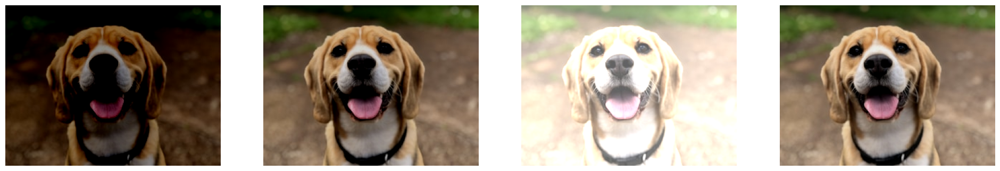

In [19]:
data_generator = ImageDataGenerator(channel_shift_range=150.0)
show_aug_image_batch(image, data_generator, n_images=4)

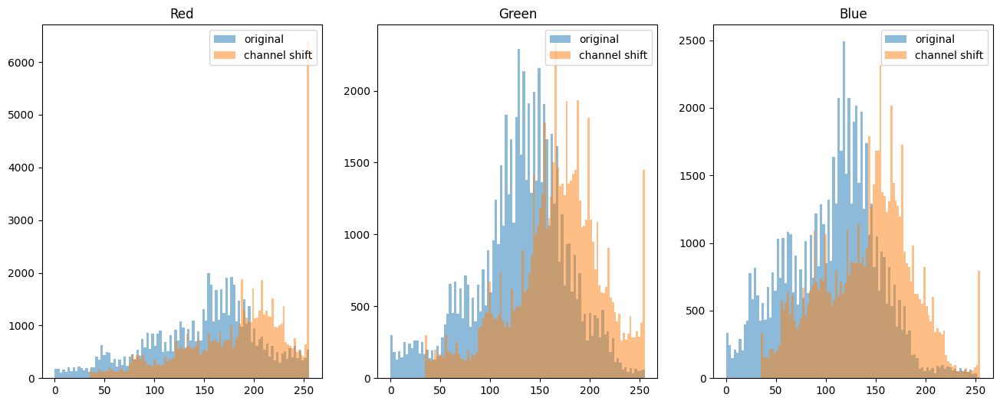

In [20]:
# 주의: aug_image를 int형으로 변환하지 않고 float으로 그대로 유지하여 반환. 
def get_aug_image(image, data_generator):
    # ImageDataGenerator는 여러개의 image를 입력으로 받음. 따라서 3차원이 아니라 batch를 포함한 4차원 array를 입력받음. np.expand_dims()로 차원 증가.
    image_batch = np.expand_dims(image, axis=0)

    # ImageDataGenerator 적용. fit()후 flow()로 image batch를 넣어주어야 함. 
    data_generator.fit(image_batch)
    data_gen_iter = data_generator.flow(image_batch)

    # ImageDataGenerator를 동작하기 위해서는 next()등으로 iteration을 호출해야함. 
    aug_image_batch = next(data_gen_iter)

    # 반환된 데이터는 batch까지 포함된 4차원 array이므로 다시 3차원 image array로 변환. 
    aug_image = np.squeeze(aug_image_batch)

    ### aug_image를 int형으로 변환하지 않고 float으로 그대로 유지.  
    aug_image = aug_image
    
    return aug_image

data_generator = ImageDataGenerator(channel_shift_range=150.0)
aug_image = get_aug_image(image, data_generator)


# RGB 모든 채널에 대해서 원본과 변환 이미지 Pixel값의 Histogram 시각화 
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))

for i in range(3):
    # i값 0 일때 Red 채널, i값 1일때 Green Channel, i값 2일때 Blue Channel Histogram 표현 
    axs[i].hist(image[:, :, i].flatten(), bins=100, alpha=0.5, label="original")
    axs[i].hist(aug_image[:, :, i].flatten(), bins=100, alpha=0.5, label="channel shift")
    axs[i].legend(loc='upper right')
    if i==0:
        title_str = 'Red'
    elif i==1:
        title_str = 'Green'
    else: 
        title_str = 'Blue'
    axs[i].set(title=title_str)

### ZCA Whitening(백색잡음역할)

In [ ]:
'''
# 실행 X
data_generator = ImageDataGenerator(zca_whitening=True, zca_epsilon=1e-05)
aug_image = get_aug_image(image, data_generator)
'''

### Normalization
일반적으로 augmentation 용도가 아닌 CNN 입력 값으로 Pixel값 변환을 위해 <br>
0~1사이의 값으로 변환하거나 채널별 Z score변환(평균:0, 표준편차:1) 적용 

- **featurewise_center**  <br>
  True이면 R,G,B **각 픽셀값**에서 **개별 채널들의 평균 픽셀값**을 빼서(-) **평균을 0으로 함**. 

- **featurewise_std_normalization**  <br>
  True이면 R,G,B **각 픽셀값**에서 **개별 채널들의 표준 편차값**으로 나눔(/). 

(참고)보통 위의 두 방법(center, std_normal...) 중 하나를 쓰게 되면, rescale 방법은 함께 쓰지 않음. <br>
- **rescale**  <br> 
  255.0 각 픽셀값을 0 ~ 1사이의 값으로 만들기 위해서 보통 255.0 으로 나눔. 

In [21]:
r_mean = np.mean(image[:, :, 0])
g_mean = np.mean(image[:, :, 1])
b_mean = np.mean(image[:, :, 2])

r_std = np.std(image[:, :, 0])
g_std = np.std(image[:, :, 1])
b_std = np.std(image[:, :, 2])

print(r_mean, g_mean, b_mean, r_std, g_std, b_std)

r_zscore = (image[:, :, 0] - r_mean)/r_std
g_zscore = (image[:, :, 1] - g_mean)/g_std
b_zscore = (image[:, :, 2] - b_mean)/b_std

148.86602962962962 131.0776148148148 106.98536296296297 55.766456332995226 46.49149000201207 46.113317356366785


In [23]:
data_generator = ImageDataGenerator(featurewise_center=True, featurewise_std_normalization=True)
image_batch = np.expand_dims(image, axis=0)

# ImageDataGenerator 적용. fit() 후 flow()로 image batch를 넣어줘야 함.
data_generator.fit(image_batch)
print(data_generator.mean, data_generator.std)

[[[148.86603 131.07762 106.98536]]] [[[55.766296 46.491516 46.110935]]]


In [24]:
data_generator = ImageDataGenerator(featurewise_center=True, featurewise_std_normalization=True)
image_batch = np.expand_dims(image, axis=0)

data_generator.fit(image_batch)
data_gen_iter = data_generator.flow(image_batch)

# ImageDataGenerator를 동작하기 위해서는 next()등으로 iteration을 호출해야 함
aug_image_batch = next(data_gen_iter)

# 반환된 데이터는 batch까지 포함된 4차원 array이므로 다시 3차원 image array로 변환
aug_image = np.squeeze(aug_image_batch)
aug_image

array([[[-1.8625233 , -1.5718485 , -1.6261947 ],
        [-1.8804553 , -1.5933578 , -1.6478815 ],
        [-1.9163193 , -1.6578858 , -1.6695684 ],
        ...,
        [-1.1631762 , -0.8405323 , -1.3442659 ],
        [-1.1990402 , -0.90506023, -1.3442659 ],
        [-1.2169721 , -0.9265695 , -1.3659527 ]],

       [[-1.8983873 , -1.6148671 , -1.6695684 ],
        [-1.9163193 , -1.6363764 , -1.6912552 ],
        [-1.9521832 , -1.7009044 , -1.712942  ],
        ...,
        [-1.1273122 , -0.7975137 , -1.3008922 ],
        [-1.1631762 , -0.8620416 , -1.3008922 ],
        [-1.1990402 , -0.90506023, -1.3442659 ]],

       [[-1.8804553 , -1.6578858 , -1.6695684 ],
        [-1.8804553 , -1.6578858 , -1.6695684 ],
        [-1.9163193 , -1.7009044 , -1.712942  ],
        ...,
        [-1.0735162 , -0.7329858 , -1.2792054 ],
        [-1.1273122 , -0.7975137 , -1.3008922 ],
        [-1.1452442 , -0.819023  , -1.3225791 ]],

       ...,

       [[ 0.63002163,  0.64360946,  0.7810434 ],
        [ 0

In [25]:
data_generator = ImageDataGenerator(rescale=1/255.0)
aug_image = get_aug_image(image, data_generator)
print(aug_image)

[[[0.1764706  0.227451   0.1254902 ]
  [0.17254902 0.22352943 0.12156864]
  [0.16470589 0.21176472 0.11764707]
  ...
  [0.32941177 0.36078432 0.1764706 ]
  [0.32156864 0.34901962 0.1764706 ]
  [0.31764707 0.34509805 0.17254902]]

 [[0.16862746 0.21960786 0.11764707]
  [0.16470589 0.21568629 0.1137255 ]
  [0.15686275 0.20392159 0.10980393]
  ...
  [0.3372549  0.36862746 0.18431373]
  [0.32941177 0.35686275 0.18431373]
  [0.32156864 0.34901962 0.1764706 ]]

 [[0.17254902 0.21176472 0.11764707]
  [0.17254902 0.21176472 0.11764707]
  [0.16470589 0.20392159 0.10980393]
  ...
  [0.34901962 0.3803922  0.18823531]
  [0.3372549  0.36862746 0.18431373]
  [0.33333334 0.3647059  0.18039216]]

 ...

 [[0.72156864 0.6313726  0.56078434]
  [0.70980394 0.61960787 0.54901963]
  [0.69411767 0.6039216  0.53333336]
  ...
  [0.6862745  0.5882353  0.50980395]
  [0.6745098  0.5882353  0.5058824 ]
  [0.67058825 0.58431375 0.5019608 ]]

 [[0.7176471  0.627451   0.5568628 ]
  [0.7058824  0.6156863  0.54509807]


### Putting all together

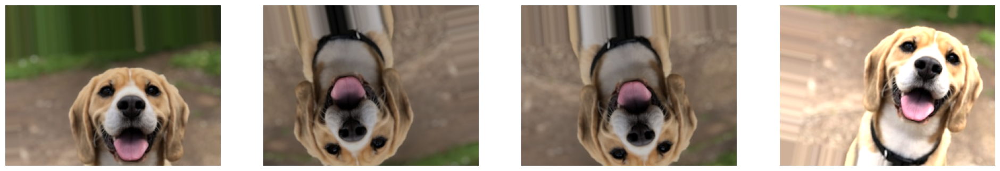

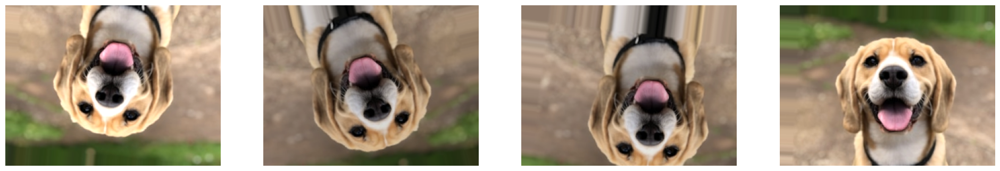

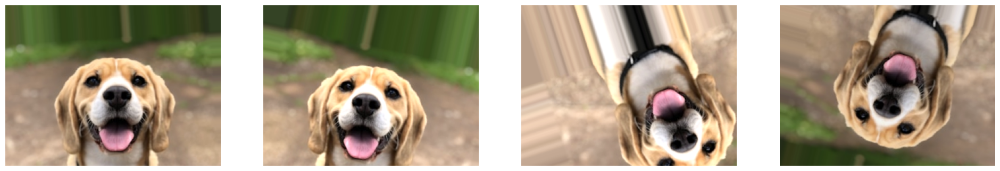

In [26]:
data_generator = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    brightness_range=(0.7, 1.3),
    horizontal_flip=True,
    vertical_flip=True,
    #rescale=1/255.0
)

show_aug_image_batch(image, data_generator, n_images=4)
show_aug_image_batch(image, data_generator, n_images=4)
show_aug_image_batch(image, data_generator, n_images=4)